[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neurogym/neurogym/blob/main/docs/examples/reinforcement_learning.ipynb)


## Neurogym with Reinforcement Learning (stable-baselines3)

NeuroGym is a toolkit that allows training any network model on many established neuroscience tasks techniques such as standard Supervised Learning or Reinforcement Learning (RL). In this notebook we will use RL to train an LSTM network on the classical Random Dots Motion (RDM) task (Britten et al. 1992).

We first show how to install the relevant toolboxes. We then show how build the task of interest (in the example the RDM task), wrapp it with the pass-reward wrapper in one line and visualize the structure of the final task. Finally we train an LSTM network on the task using the A2C algorithm [Mnih et al. 2016](https://arxiv.org/abs/1602.01783) implemented in the [stable-baselines3](https://stable-baselines3.readthedocs.io/en/master/) toolbox, and plot the results.

It is straightforward to change the code to train a network on any other available task or using a different RL algorithm (e.g. ACER, PPO2).


### Installation

**Google Colab:** Uncomment and execute cell below when running this notebook on google colab.

**Local:** Follow [these instructions](https://github.com/neurogym/neurogym?tab=readme-ov-file#installation) when running
this notebook locally.


In [1]:
# ! pip install neurogym[rl]

### Import libraries


In [2]:
import neurogym as ngym
from neurogym.wrappers import pass_reward
import warnings
from IPython.display import clear_output
clear_output()
warnings.filterwarnings('ignore')

### Task


here we build the Random Dots Motion task, specifying the duration of each trial period (fixation, stimulus, decision) and wrapp it with the pass-reward wrapper which appends the previous reward to the observation. We then plot the structure of the task in a figure that shows:

1. The observations received by the agent (top panel).
2. The actions taken by a random agent and the correct action at each timestep (second panel).
3. The rewards provided by the environment at each timestep (third panel).
4. The performance of the agent at each trial (bottom panel).


<OrderEnforcing<PerceptualDecisionMaking>>


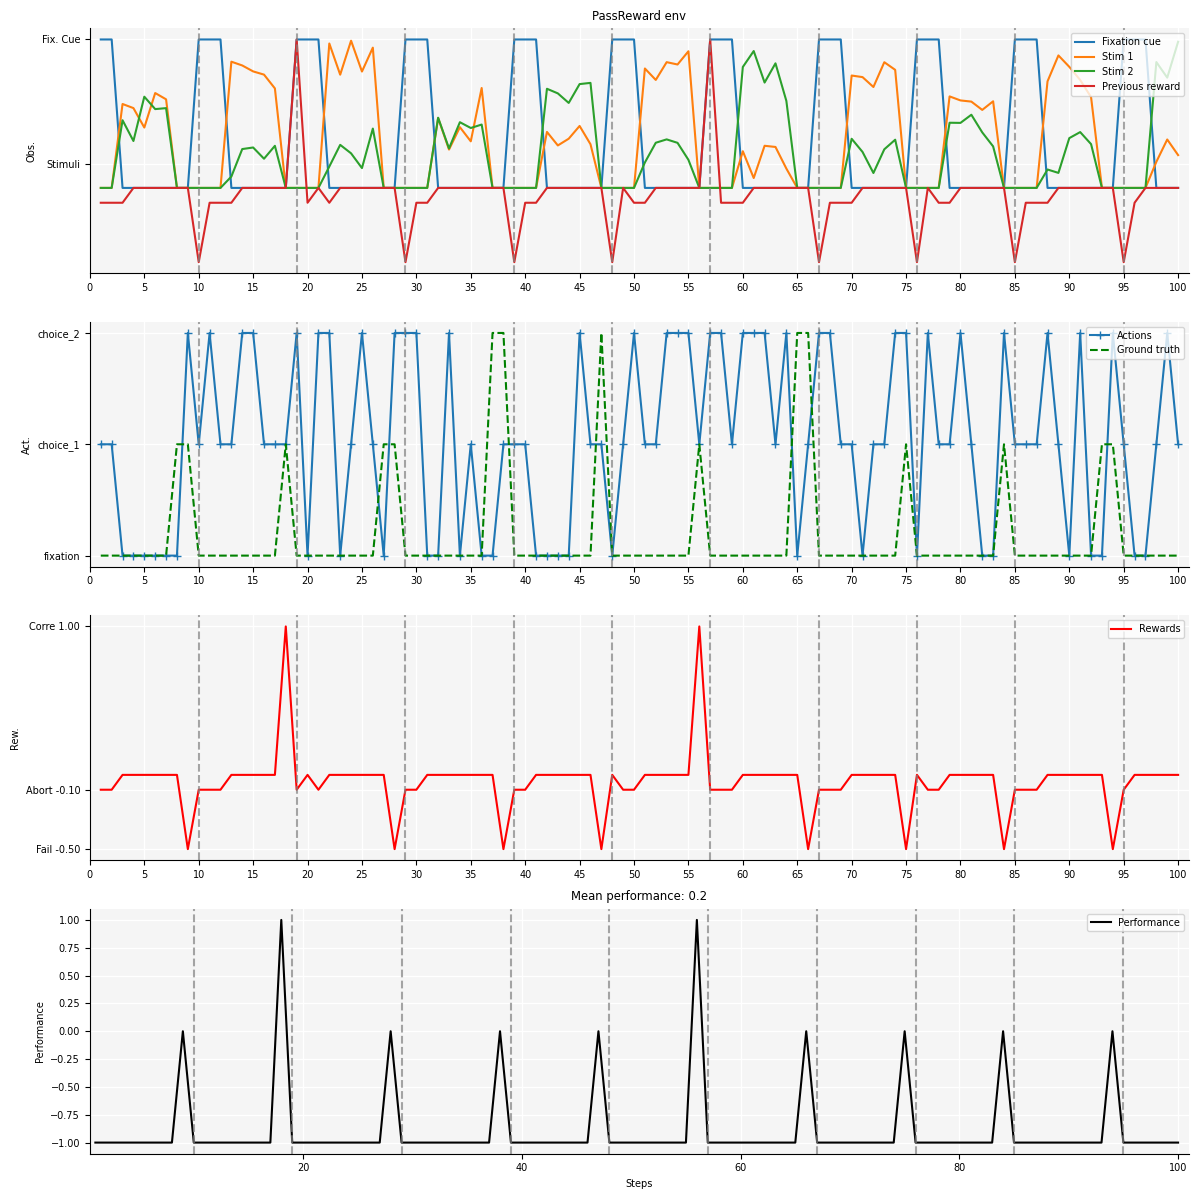

In [3]:
# Task name
name = 'PerceptualDecisionMaking-v0'
# task specification (here we only specify the duration of the different trial periods)
timing = {
    'fixation': ('constant', 300),
    'stimulus': ('constant', 500),
    'decision': ('constant', 300),
}
kwargs = {'dt': 100, 'timing': timing}
# build task
env = ngym.make(name, **kwargs)
# print task properties
print(env)
# wrapp task with pass-reward wrapper
env = pass_reward.PassReward(env)
# plot example trials with random agent
_ = ngym.utils.plot_env(
    env,
    fig_kwargs={'figsize': (12, 12)},
    num_steps=100,
    ob_traces=['Fixation cue', 'Stim 1', 'Stim 2', 'Previous reward'],
)

In [4]:
policy_kwargs = {
    "lstm_hidden_size": 64,      # Small LSTM for short sequences
    "n_lstm_layers": 1,           # Single layer is sufficient
    "shared_lstm": False,          # Share LSTM to reduce parameters
    "enable_critic_lstm": False,  # Disable separate LSTM for critic when sharing
    "EISep": True,  # Enable E/I separation
}

### Train a network


In [5]:
# these values are set low for testing purposes. To get a better sense of the package, we recommend setting
# `total_timesteps = 100_000`
total_timesteps = 100000
log_interval = 1000

from sb3_contrib import RecurrentPPO
from stable_baselines3.common.vec_env import DummyVecEnv

env = DummyVecEnv([lambda: env])

model = RecurrentPPO(
    policy="MlpLstmPolicy",
    env=env,
    verbose=1,
    policy_kwargs=policy_kwargs,
    ent_coef=0.01,  # Entropy coefficient for exploration
    clip_range=0.2,
    tensorboard_log='./log/perceptualdecisionmaking'  # TensorBoard log directory
)
_, reward_ar = model.learn(total_timesteps=total_timesteps, log_interval=log_interval)
env.close()

Using cuda device
Using EISepLSTM
Logging to ./log/perceptualdecisionmaking/RecurrentPPO_36
Training iteration 0 / 100000 timesteps, 0, temperature: 1.0
Training iteration 1 / 100000 timesteps, 128, temperature: 0.9936268159427698
Training iteration 2 / 100000 timesteps, 256, temperature: 0.9872942900187002
Training iteration 3 / 100000 timesteps, 384, temperature: 0.9810021628466439
Training iteration 4 / 100000 timesteps, 512, temperature: 0.9747501767001922
Training iteration 5 / 100000 timesteps, 640, temperature: 0.9685380754971183
Training iteration 6 / 100000 timesteps, 768, temperature: 0.9623656047888888
Training iteration 7 / 100000 timesteps, 896, temperature: 0.9562325117502403
Training iteration 8 / 100000 timesteps, 1024, temperature: 0.9501385451688242
Training iteration 9 / 100000 timesteps, 1152, temperature: 0.9440834554349178
Training iteration 10 / 100000 timesteps, 1280, temperature: 0.9380669945311987
Training iteration 11 / 100000 timesteps, 1408, temperature: 0.

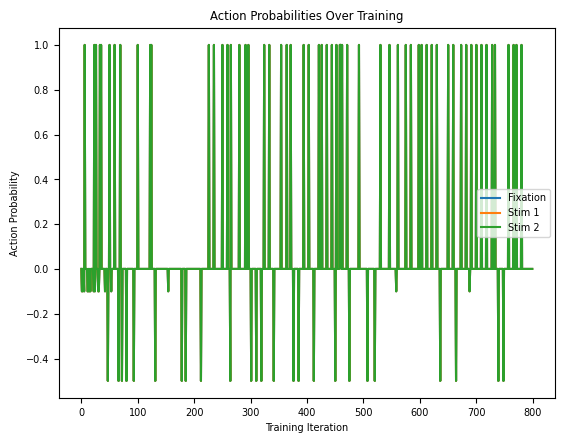

In [6]:
from matplotlib import pyplot as plt
reward_ar_np = reward_ar.detach().cpu().numpy()
plt.plot(reward_ar_np[:800,0], label='Fixation')
plt.plot(reward_ar_np[:800,1], label='Stim 1')
plt.plot(reward_ar_np[:800,2], label='Stim 2')
plt.xlabel('Training Iteration')
plt.ylabel('Action Probability')
plt.title('Action Probabilities Over Training')
plt.legend()
plt.show()

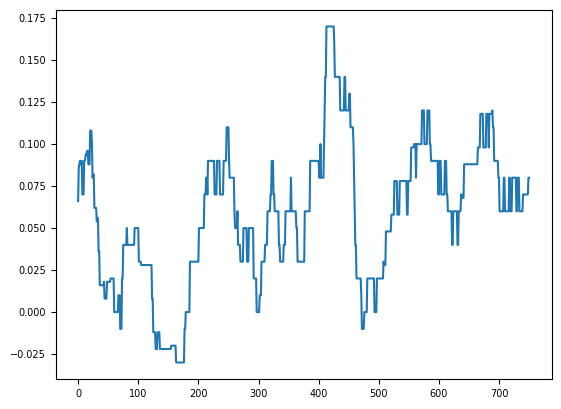

In [7]:
import numpy as np
sliding_window = 50
smoothed_reward = reward_ar_np[:800, 0].copy()
smooth = np.convolve(smoothed_reward, np.ones(sliding_window)/sliding_window, mode='valid')
plt.plot(smooth, label='Smoothed Fixation Action Probability')

In [8]:
# total_timesteps = 100000
# log_interval = 500

# from sb3_contrib import RecurrentPPO
# from stable_baselines3.common.vec_env import DummyVecEnv
# import torch as th
# # env = DummyVecEnv([lambda: env])
# model = RecurrentPPO(
#     policy="MlpLstmPolicy",
#     env=env,
#     verbose=1,
#     policy_kwargs=policy_kwargs,
#     ent_coef=0.1,  # Entropy coefficient for exploration
#     tensorboard_log='./log/perceptualdecisionmaking'  # TensorBoard log directory
# )
# model.policy.load_state_dict(th.load('./model/perceptualdecisionmaking/rl_ppo_recurrent_policy_gumbelsoftmax.pth'))


### Visualize results


<OrderEnforcing<PerceptualDecisionMaking>>
testing, temperature= -1
distribution: tensor([[9.9857e-01, 1.0395e-03, 3.9366e-04]], device='cuda:0')
testing, temperature= -1
distribution: tensor([[9.9842e-01, 1.0552e-03, 5.2899e-04]], device='cuda:0')
testing, temperature= -1
distribution: tensor([[0.2021, 0.4700, 0.3279]], device='cuda:0')
testing, temperature= -1
distribution: tensor([[0.0060, 0.9828, 0.0112]], device='cuda:0')
testing, temperature= -1
distribution: tensor([[0.0025, 0.9856, 0.0119]], device='cuda:0')
testing, temperature= -1
distribution: tensor([[0.0012, 0.9935, 0.0053]], device='cuda:0')
testing, temperature= -1
distribution: tensor([[0.0024, 0.9948, 0.0028]], device='cuda:0')
testing, temperature= -1
distribution: tensor([[0.0025, 0.2877, 0.7098]], device='cuda:0')
testing, temperature= -1
distribution: tensor([[9.9890e-01, 4.7270e-04, 6.2258e-04]], device='cuda:0')
testing, temperature= -1
distribution: tensor([[9.9852e-01, 9.3624e-04, 5.3962e-04]], device='cuda:0')

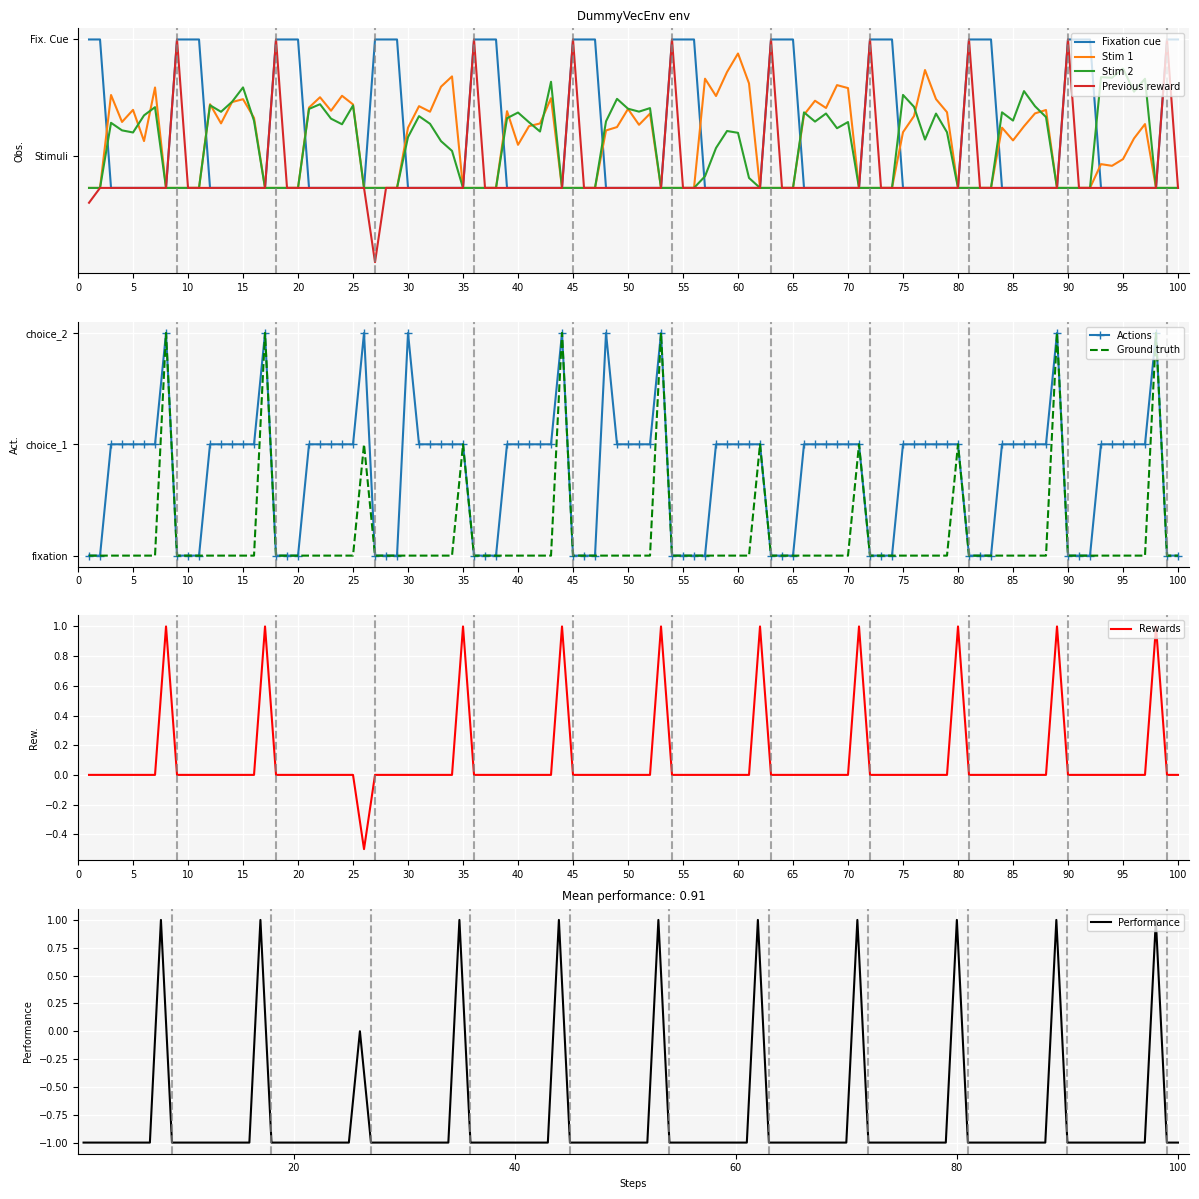

In [9]:
env = ngym.make(name, **kwargs)
# print task properties
print(env)
# wrapp task with pass-reward wrapper
env = pass_reward.PassReward(env)
env = DummyVecEnv([lambda: env])

# plot example trials with random agent
_ = ngym.utils.plot_env(
    env,
    fig_kwargs={'figsize': (12, 12)},
    num_steps=100,
    ob_traces=['Fixation cue', 'Stim 1', 'Stim 2', 'Previous reward'],
    model=model,
)


In [10]:
print(model.policy.lstm_actor.eimask_logit)

Parameter containing:
tensor([[ 2.3413, -2.3098],
        [ 2.3535, -2.3382],
        [ 2.2607, -2.4158],
        [ 2.2982, -2.3868],
        [ 2.3627, -2.2806],
        [-2.3496,  2.3180],
        [-2.3501,  2.3150],
        [ 2.4418, -2.2122],
        [ 2.2818, -2.3530],
        [-2.2226,  2.4200],
        [-2.2796,  2.4010],
        [-2.4196,  2.2723],
        [ 2.3718, -2.2898],
        [ 2.3702, -2.3177],
        [ 2.3737, -2.2866],
        [-2.2982,  2.3457],
        [-2.5425,  2.1066],
        [-2.3851,  2.2711],
        [-2.3641,  2.2562],
        [ 2.3782, -2.3080],
        [ 2.3777, -2.3137],
        [-2.2950,  2.3931],
        [-2.2311,  2.4272],
        [-2.3837,  2.3064],
        [ 2.4029, -2.2454],
        [-2.3949,  2.2895],
        [ 2.2686, -2.4070],
        [-2.2351,  2.4561],
        [-2.4265,  2.2427],
        [-2.3578,  2.3245],
        [ 2.4136, -2.2526],
        [-2.3515,  2.3415],
        [-2.3327,  2.3024],
        [ 2.2913, -2.3811],
        [ 2.3243, -2.3298]

In [36]:
import torch as th
th.save(model.policy.state_dict(), './model/perceptualdecisionmaking/rl_ppo_recurrent_policy_gumbelsoftmax_entropy10.pth')

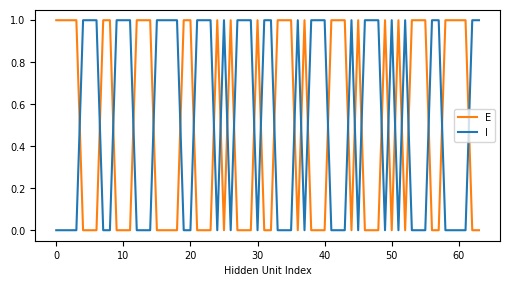

In [35]:
import matplotlib.pyplot as plt
import torch as th
from torch.nn import functional as F
eimask_logit = model.policy.lstm_actor.eimask_logit
# mask = (eimask_logit/0.001).softmax(dim=-1)  # (H, 2)
# mask = np.where(eimask_logit[:,0:1] > eimask_logit[:,1:], np.array([[1,0]]).repeat(64,0),
#                 np.array([[0,1]]).repeat(64,0))  # (H, 2)
mask = F.gumbel_softmax(eimask_logit, tau=0.01, hard=False, dim=-1)  # (H, 2)
mask_to_plot = mask.detach().cpu().numpy()
plt.figure(figsize=(6, 3))
plt.plot(mask_to_plot[:, 0], label='E', color='C1')
plt.plot(mask_to_plot[:, 1], label='I', color='C0')
plt.xlabel('Hidden Unit Index')
plt.legend()

In [13]:
print(eimask_logit)

Parameter containing:
tensor([[ 2.3413, -2.3098],
        [ 2.3535, -2.3382],
        [ 2.2607, -2.4158],
        [ 2.2982, -2.3868],
        [ 2.3627, -2.2806],
        [-2.3496,  2.3180],
        [-2.3501,  2.3150],
        [ 2.4418, -2.2122],
        [ 2.2818, -2.3530],
        [-2.2226,  2.4200],
        [-2.2796,  2.4010],
        [-2.4196,  2.2723],
        [ 2.3718, -2.2898],
        [ 2.3702, -2.3177],
        [ 2.3737, -2.2866],
        [-2.2982,  2.3457],
        [-2.5425,  2.1066],
        [-2.3851,  2.2711],
        [-2.3641,  2.2562],
        [ 2.3782, -2.3080],
        [ 2.3777, -2.3137],
        [-2.2950,  2.3931],
        [-2.2311,  2.4272],
        [-2.3837,  2.3064],
        [ 2.4029, -2.2454],
        [-2.3949,  2.2895],
        [ 2.2686, -2.4070],
        [-2.2351,  2.4561],
        [-2.4265,  2.2427],
        [-2.3578,  2.3245],
        [ 2.4136, -2.2526],
        [-2.3515,  2.3415],
        [-2.3327,  2.3024],
        [ 2.2913, -2.3811],
        [ 2.3243, -2.3298]

In [14]:
import torch as th
import numpy as np
Wrec_free = model.policy.lstm_actor.Wrec_free
Wrec = model.policy.lstm_actor.rec_filter(Wrec_free)  # (H, H)
# ei_code = th.where(eimask_logit[:,0] > eimask_logit[:,1], 1., -1.)
ei_code = mask[:, 0] - mask[:, 1]  # (H, )
actual = Wrec @ th.diag(ei_code)

Excitatory Ratio: 0.50


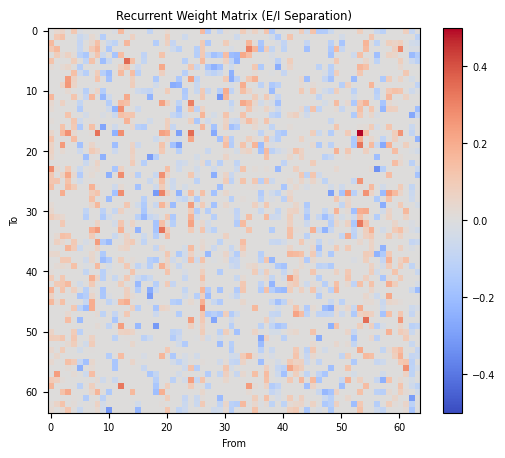

In [15]:
excitatory_ratio = (ei_code > 0).float().mean().item()
print(f'Excitatory Ratio: {excitatory_ratio:.2f}')
plt.figure(figsize=(6, 5))
plt.imshow(actual.detach().cpu().numpy(), cmap='coolwarm', aspect='auto', vmax=0.5, vmin=-0.5)
plt.colorbar()
plt.title('Recurrent Weight Matrix (E/I Separation)')
plt.xlabel('From')
plt.ylabel('To')
plt.savefig('./output/recurrent_weight_matrix_ei_separation.png', dpi=300, bbox_inches='tight')
plt.show()
